#**Facial Emotion Recognition**

#<b>Problem Definition</b>
##<b>The context<b>:



---


##<b>Objectives<b>:
Create a computervision model that can accurately detect facial emotions.The model will perform multi-class classification on images of facial expressions,to classify the expressions according to the associated emotion.


---


##<b>The key questions:<b>



---


##<b>Problem formulation<b>:



---


##<b>Data Description </b>
The data set consists of 3 folders:'test','train', and'validation'

*   **"test"**
*   **"train"**
*   **"validation"**

**Each of these folders has four subfolders:**

*   **"happy"**:  *Images ofpeople who have happy facial expressions.*
*   **"sad"**:    *Images of people with sad or upset facial expressions.*
*   **"surprise"**:*Images of people who have shocked or surprised facial expressions.*
*   **"neutral"**: *Images of people showing no prominent emotionin their facial expression at all.*






#**Exploratory Data Analysis**

###**Mount the drive**

In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


###**Import Libraries**

In [2]:
#operating system functionality
import os
#zipfile access
import zipfile

#image processing
from PIL import Image
import cv2

#data wrangling
import numpy as np
import pandas as pd

#data viz
import matplotlib.pyplot as plt
import seaborn as sns

#hide warnings
import warnings
warnings.filterwarnings('ignore')

#renders the figure in the notebook
%matplotlib inline

###**Import data**

In [3]:
#Ziped data path
datapath = '/content/drive/MyDrive/trainings/MIT/notebook/post_training_study/facial_emotion/Facial_emotion_images.zip'
#File extraction
with zipfile.ZipFile(datapath,'r') as unzip:
  unzip.extractall()

In [4]:
#Unziped data path
path = '/content/Facial_emotion_images'

#Create lists matching the name of the folders to loop through
folders = ["/" + f + "/" for f in os.listdir(path)]
subfolders = ["/" + s + "/" for s in os.listdir(path + "/" + folders[0])]

print(folders)
print(subfolders)

['/test/', '/train/', '/validation/']
['/happy/', '/sad/', '/surprise/', '/neutral/']


#**Data preparation & Exploratory analysis**

In [5]:
#Init lists to store the data:
train_data = []
train_labels = []
test_data = []
test_labels = []
val_data = []
val_labels = []

#Loop through folders
for f in folders:
  #Loop through subfolders
  for s in subfolders:
    #Store image data path
    img_dpath = os.listdir(path + f + s)
    #Loop through image data
    for ipth in img_dpath:
      #Read image
      img = cv2.imread(path + f + s + ipth)
      #Convert the image to an Numpy array
      img = np.array(img)
      #Encode labels & add images to the correct list based on the folder's name for each set
      label = [0, 0, 0, 0]
      label[subfolders.index(s)] = 1
      if f == '/train/':
        train_data.append(img)
        train_labels.append(label)
      if f == '/test/':
        test_data.append(img)
        test_labels.append(label)
      if f == '/validation/':
        val_data.append(img)
        val_labels.append(label)

In [6]:
#Convert the resulted list to Numpy array
train_data = np.array(train_data)
test_data = np.array(test_data)
train_labels = np.array(train_labels)
test_labels = np.array(test_labels)

###**Visualize image data**

In [7]:
#Data Normalization
train_data = (train_data / 255).astype('float32')
test_data = (test_data / 255).astype('float32')

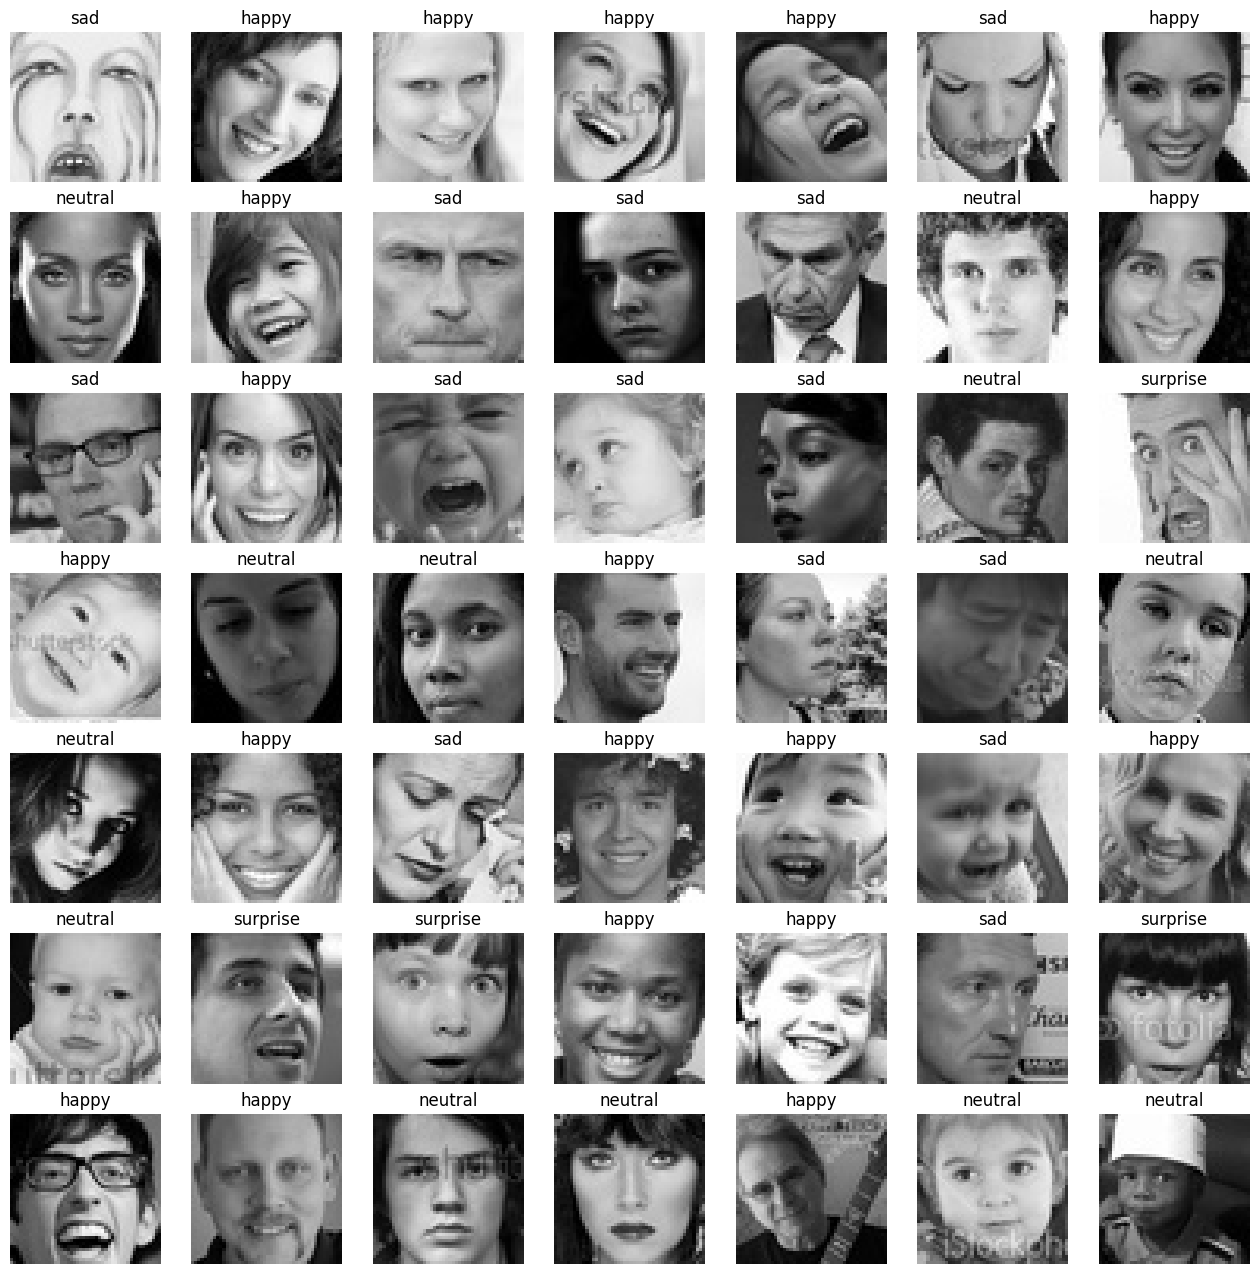

In [8]:
#Setting seed
np.random.seed(16)
#Set plot dimensions
plt.figure(figsize=(16, 16))
#Randomly show 36 images for each category from the dataset
for i in range(49):
  #Compute random index
  index = int(np.random.randint(0, train_labels.shape[0], 1))
  #Define plot shape
  plt.subplot(7,7, i + 1)
  #Show image
  plt.imshow(train_data[index])
  #Show caption accordingly to the images index
  plt.title(subfolders[np.argmax(train_labels[index])][1:-1])
  plt.axis('off')
plt.show()

**Noticeable variation**
*   Head orientation
*   Head tilt
*   Zoom ratio
*   Skin tone
*   Lighting scenario (shadows, light angle, image brightness)
*   Contrast
*   Props (cigar, glasses, hats, ...)
*   Hidden features
*   Age -> features ratio to each other
*   Watermarks

In [16]:
##Define a common set of colors for the plots
#Emotions colors
colors = ['coral', 'burlywood', 'lightseagreen', 'cadetblue']

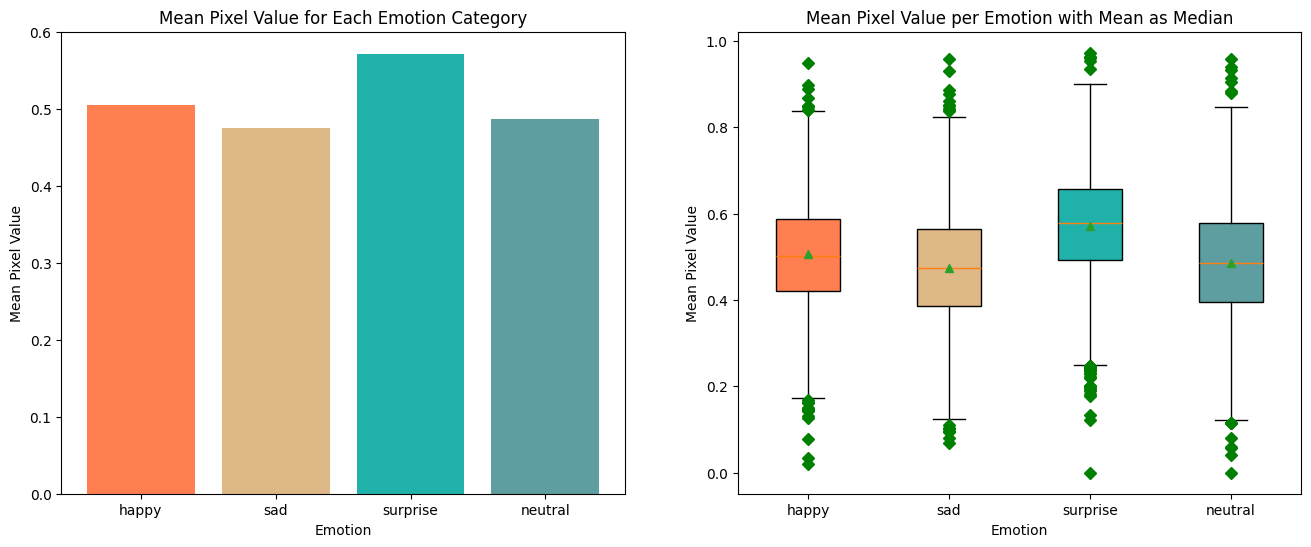

In [15]:
#Compute the mean pixel value for each emotion category
mean_pixel_values = []
for i in range(len(subfolders)):
    # Get indices of the current emotion in the training data
    emotion_indices = np.where(np.all(train_labels == [1 if j == i else 0 for j in range(len(subfolders))], axis=1))[0]
    #Get the images for the current emotion
    emotion_images = train_data[emotion_indices]
    #Calculate the mean pixel value for the emotion
    mean_value = np.mean(emotion_images)
    mean_pixel_values.append(mean_value)
#Get the emotion labels
emotion_labels_gp = [s[1:-1] for s in subfolders]

#Compute the mean pixel value for each image
mean_px_val_per_data = []
emotion_labels = []
for t in train_data:
  mean_px_val_per_data.append(np.mean(t))
#Create a list of emotion labels
emotion_labels_for_boxplot = [subfolders[np.argmax(label)][1:-1] for label in train_labels]

# Extract mean pixel values for each emotion category for the boxplot
boxplot_data = []
for label in emotion_labels_gp:
    # Get the indices in mean_px_val_per_data that correspond to the current emotion label
    indices = [i for i, l in enumerate(emotion_labels_for_boxplot) if l == label]
    # Append the mean pixel values for these indices to the boxplot_data list
    boxplot_data.append([mean_px_val_per_data[i] for i in indices])


#Plot dimensions
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16,6))
#Create bar plot
axes[0].bar(emotion_labels_gp, mean_pixel_values, color=colors)
axes[0].set_xlabel("Emotion")
axes[0].set_ylabel("Mean Pixel Value")
axes[0].set_title("Mean Pixel Value for Each Emotion Category")
#Create scatter plot
boxplot = axes[1].boxplot(boxplot_data, labels=emotion_labels_gp, patch_artist=True, showmeans=True, sym='gD')
axes[1].set_xlabel("Emotion")
axes[1].set_ylabel("Mean Pixel Value")
axes[1].set_title("Mean Pixel Value per Emotion with Mean as Median")
#Set color to boxplot
for patch, color in zip(boxplot['boxes'], colors):
    patch.set_facecolor(color)

plt.show()

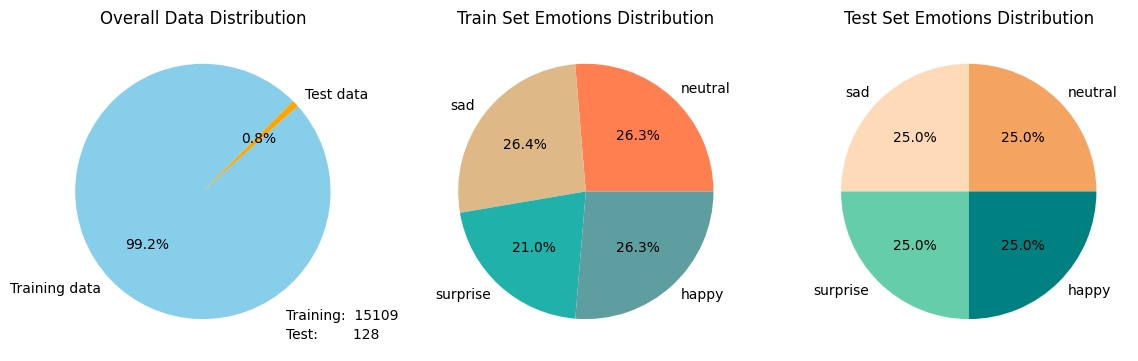

In [ ]:
# Count the number of values for each categories in training data
train_num = train_data.shape[0]
test_num = test_data.shape[0]

#Count the occurrences of each emotion in the training labels
train_emotion_counts = np.sum(train_labels, axis=0)
#Count the occurrences of each emotion in the test labels
test_emotion_counts = np.sum(test_labels, axis=0)
# Get the emotion labels from the subfolders list
emotion_labels = [s[1:-1] for s in subfolders]

#Plot dimensions
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14,10))
#Plot A
axes[0].pie([train_num, test_num], labels=["Training data", "Test data"], autopct="%1.1f%%", colors=['skyblue', 'orange'], startangle=45)
axes[0].set_title("Overall Data Distribution")
axes[0].text(0.65, -1, ("Training:  " + str(train_num)))
axes[0].text(0.65, -1.15, ("Test:        " + str(test_num)))
#Plot B
axes[1].pie(train_emotion_counts, labels=emotion_labels, autopct="%1.1f%%", colors=colors, startangle=0)
axes[1].set_title("Train Set Emotions Distribution")
#Plot C
axes[2].pie(test_emotion_counts, labels=emotion_labels, autopct="%1.1f%%", colors=colors, startangle=0)
axes[2].set_title("Test Set Emotions Distribution")

plt.show()

* The Test dataset represent 0.8% of the data
* The Train-Test split is unbalanced
* There is 5.3% less data from the 'Surprise' category comparing to the others in the training Data set
* Emotions category are balanced in Test dataset

##**Fixing Data unbalance**

In [ ]:
# Calculate the number of samples to remove from each category
sad_to_remove = int(len(train_data) * 0.0535)
happy_to_remove = int(len(train_data) * 0.053)
neutral_to_remove = int(len(train_data) * 0.053)
                                                                      #Category reminder: ['/neutral/', '/sad/', '/surprise/', '/happy/']
# Get the indices of each category
sad_indices = np.where(np.all(train_labels == [0, 1, 0, 0], axis=1))[0]
happy_indices = np.where(np.all(train_labels == [0, 0, 0, 1], axis=1))[0]
neutral_indices = np.where(np.all(train_labels == [1, 0, 0, 0], axis=1))[0]

# Randomly select indices to remove from each category
remove_sad_indices = np.random.choice(sad_indices, sad_to_remove, replace=False)
remove_happy_indices = np.random.choice(happy_indices, happy_to_remove, replace=False)
remove_neutral_indices = np.random.choice(neutral_indices, neutral_to_remove, replace=False)

# Combine the indices to remove
indices_to_remove = np.concatenate([remove_sad_indices, remove_happy_indices, remove_neutral_indices])

# Create new data and labels arrays by excluding the selected indices
train_data = np.delete(train_data, indices_to_remove, axis=0)
train_labels = np.delete(train_labels, indices_to_remove, axis=0)

In [ ]:
# Calculate the total number of images
total_images = len(train_data) + len(test_data)

# Calculate the number of images to transfer
num_to_transfer = int(total_images * 0.19)

# Calculate the proportion of each emotion in the training data
train_emotion_counts = np.sum(train_labels, axis=0)
emotion_proportions = train_emotion_counts / len(train_data)

# Calculate the number of images to transfer for each emotion category
transfer_counts = (emotion_proportions * num_to_transfer).astype(int)

# Transfer images from train to test for each emotion category
for i in range(len(subfolders)):
    # Get indices of the current emotion in the training data
    emotion_indices = np.where(np.all(train_labels == [1 if j == i else 0 for j in range(len(subfolders))], axis=1))[0]

    # Randomly select indices to transfer
    transfer_indices = np.random.choice(emotion_indices, transfer_counts[i], replace=False)

    # Append selected data and labels to the test set
    test_data = np.concatenate((test_data, train_data[transfer_indices]), axis=0)
    test_labels = np.concatenate((test_labels, train_labels[transfer_indices]), axis=0)

    # Remove transferred data and labels from the training set
    train_data = np.delete(train_data, transfer_indices, axis=0)
    train_labels = np.delete(train_labels, transfer_indices, axis=0)

# Verify the new counts
print("Train data shape after transfer:", train_data.shape)
print("Test data shape after transfer:", test_data.shape)

train_emotion_counts_after_transfer = np.sum(train_labels, axis=0)
test_emotion_counts_after_transfer = np.sum(test_labels, axis=0)

print("Train Set Emotions Distribution after transfer:", train_emotion_counts_after_transfer)
print("Test Set Emotions Distribution after transfer:", test_emotion_counts_after_transfer)

Train data shape after transfer: (10266, 48, 48, 3)
Test data shape after transfer: (2563, 48, 48, 3)
Train Set Emotions Distribution after transfer: [2569 2565 2565 2567]
Test Set Emotions Distribution after transfer: [641 641 640 641]


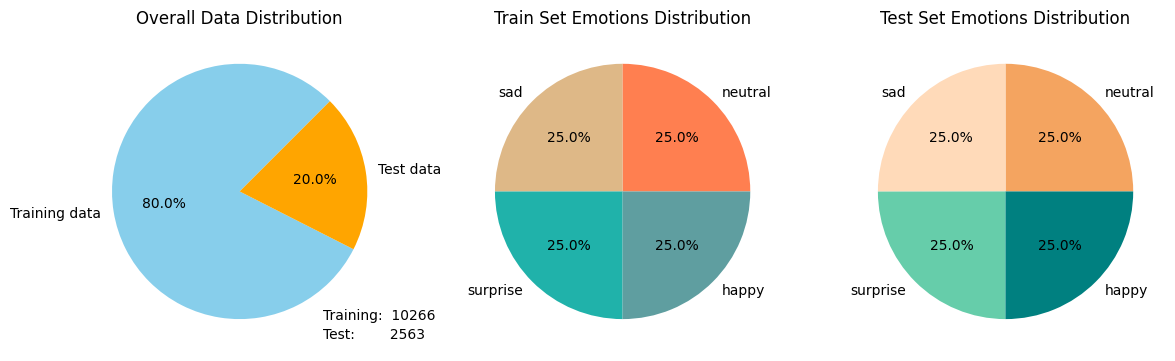

In [ ]:
# Count the number of values for each categories in training data
train_num = train_data.shape[0]
test_num = test_data.shape[0]

#Count the occurrences of each emotion in the training labels
train_emotion_counts = np.sum(train_labels, axis=0)
#Count the occurrences of each emotion in the test labels
test_emotion_counts = np.sum(test_labels, axis=0)
# Get the emotion labels from the subfolders list
emotion_labels = [s[1:-1] for s in subfolders]

#Plot dimensions
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14,10))
#Plot A
axes[0].pie([train_num, test_num], labels=["Training data", "Test data"], autopct="%1.1f%%", colors=['skyblue', 'orange'], startangle=45)
axes[0].set_title("Overall Data Distribution")
axes[0].text(0.65, -1, ("Training:  " + str(train_num)))
axes[0].text(0.65, -1.15, ("Test:        " + str(test_num)))
#Plot B
axes[1].pie(train_emotion_counts, labels=emotion_labels, autopct="%1.1f%%", colors=colors, startangle=0)
axes[1].set_title("Train Set Emotions Distribution")
#Plot C
axes[2].pie(test_emotion_counts, labels=emotion_labels, autopct="%1.1f%%", colors=colors, startangle=0)
axes[2].set_title("Test Set Emotions Distribution")

plt.show()

*   Data is now balanced between train and test sets with a 80-20% split
*   Category are now balanced accross the train set
*   Some data have been deleted wich can be bad for smaller dataset
*   Data augmentation will be usefull to compensate the loss in data

##**Data Augmentation**

####**Train Data Augmentation**

In [ ]:
#Import usefull library
from tensorflow.keras.preprocessing.image import load_img, img_to_array, ImageDataGenerator

#Define number of variation
variation_number = 2

#Create image data augmentation generator
datagenerator = ImageDataGenerator(horizontal_flip=True, vertical_flip=True, rotation_range=(180/variation_number))

In [ ]:
#Create lists to store the data augmentation result
train_data_augmented = []
train_labels_augmented = []

#Loop through train set, process the image data and store the result and the associated labels
for i, x in enumerate(train_data):
  data = img_to_array(x)
  # expand dimension to one sample
  samples = np.expand_dims(data, 0)

  #Set Iterator
  iter = datagenerator.flow(samples, batch_size=1)
  #Image Processing
  for j in range(variation_number):
    batch = next(iter)
    # Remove the extra dimension from the batch
    augmented_image = batch[0].astype('float32')
    #Add result image data to its list
    train_data_augmented.append(augmented_image)
    #Add the associated label to its list
    train_labels_augmented.append(train_labels[i])
#Convert to Numpy array
train_data_augmented = np.array(train_data_augmented)
train_labels_augmented = np.array(train_labels_augmented)

In [ ]:
#Concatenate augmented image data with original image data
train_data = np.concatenate((train_data, train_data_augmented), axis=0)
train_labels = np.concatenate((train_labels, train_labels_augmented), axis=0)
#Print shape
train_data.shape, train_labels.shape

((30798, 48, 48, 3), (30798, 4))

####**Test Data Augmentation**

In [ ]:
#Create lists to store the data augmentation result
test_data_augmented = []
test_labels_augmented = []
#Loop through train set, process the image data and store the result and the associated labels
for i, x in enumerate(test_data):
  data = img_to_array(x)
  # expand dimension to one sample
  samples = np.expand_dims(data, 0)
  #Set Iterator
  iter = datagenerator.flow(samples, batch_size=1)
  #Image Processing
  for j in range(variation_number):
    batch = next(iter)
    # Remove the extra dimension from the batch
    augmented_image = batch[0].astype('float32')
    #Add result image data to its list
    test_data_augmented.append(augmented_image)
    #Add the associated label to its list
    test_labels_augmented.append(test_labels[i])
#Convert to Numpy array
test_data_augmented = np.array(test_data_augmented)
test_labels_augmented = np.array(test_labels_augmented)

In [ ]:
#Concatenate augmented image data with original image data
test_data = np.concatenate((test_data, test_data_augmented), axis=0)
test_labels = np.concatenate((test_labels, test_labels_augmented), axis=0)
#Print shape
test_data.shape, test_labels.shape

((7689, 48, 48, 3), (7689, 4))

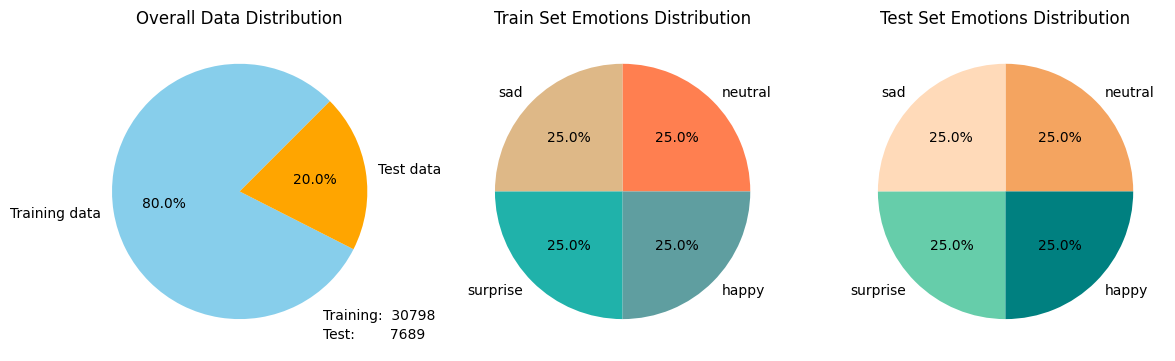

In [ ]:
# Count the number of values for each categories in training data
train_num = train_data.shape[0]
test_num = test_data.shape[0]

#Count the occurrences of each emotion in the training labels
train_emotion_counts = np.sum(train_labels, axis=0)
#Count the occurrences of each emotion in the test labels
test_emotion_counts = np.sum(test_labels, axis=0)
# Get the emotion labels from the subfolders list
emotion_labels = [s[1:-1] for s in subfolders]

#Plot dimensions
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14,10))
#Plot A
axes[0].pie([train_num, test_num], labels=["Training data", "Test data"], autopct="%1.1f%%", colors=['skyblue', 'orange'], startangle=45)
axes[0].set_title("Overall Data Distribution")
axes[0].text(0.65, -1, ("Training:  " + str(train_num)))
axes[0].text(0.65, -1.15, ("Test:        " + str(test_num)))
#Plot B
axes[1].pie(train_emotion_counts, labels=emotion_labels, autopct="%1.1f%%", colors=colors, startangle=0)
axes[1].set_title("Train Set Emotions Distribution")
#Plot C
axes[2].pie(test_emotion_counts, labels=emotion_labels, autopct="%1.1f%%", colors=colors, startangle=0)
axes[2].set_title("Test Set Emotions Distribution")

plt.show()